# Schottky Mapper


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib_scalebar.scalebar import ScaleBar
import matplotlib as mpl
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.sans-serif'] = ['Arial']
import h5py

In [22]:
import sys
from pathlib import Path
import numpy as np
# 設定專案根目錄
PROJECT_ROOT = Path('/home/tim/python/dataProcess/nanonis/ivs')

# 添加模組路徑
sys.path.insert(0, str(PROJECT_ROOT / 'schottky' / 'modules'))
sys.path.insert(0, str(PROJECT_ROOT / 'src'))

# 匯入需要的模組
from h5utils_optimized import HDF5Analyzer
from schottky_analyzer import SchottkyAnalyzer
from schottky_mapper import SchottkyMapper

# 載入 HDF5 數據
import os
# source 
root_path  ='/home/tim/Documents/AS/data/nanonis2/2024/20240508/2 um 100 pix bias spec map2'
filename = "2 um 100 pix bias spec map2.h5"

h5map_path = os.path.join(root_path, filename)

h5map = HDF5Analyzer(h5map_path)

# 查看結構
h5map.list_structure()

# 取得摘要
print("\nSummary:")
summary = h5map.summary()

h5map.print_usage()

# 創建 SchottkyAnalyzer 實例
temperature = 300.0  # K
a_star = 54.0  # A/cm^2·K^2 for MoS2
schottky_analyzer = SchottkyAnalyzer(temperature=temperature, a_star=a_star)

# 計算接觸面積 (範例: 25nm 直徑)
d_nm = 25
area_cm2 = np.pi * (d_nm/2 * 1e-7)**2  # 轉換為 cm^2

# 現在創建 SchottkyMapper
mapper = SchottkyMapper(h5map, schottky_analyzer, area_cm2)

DATASET: bias (Shape: (500,), Dtype: float64)
DATASET: current_fwd (Shape: (500, 10000), Dtype: float64)

METADATA:
  Experiment: Bias-Spectroscopy-Current-Map-fwd
  Bias Points: 500
  Pixels: 100 x 100
  Range: 2.00e-06 x 2.00e-06 m

Summary:
📋 數據摘要
----------------------------------------
文件: 2 um 100 pix bias spec map2.h5
路徑: /home/tim/Documents/AS/data/nanonis2/2024/20240508/2 um 100 pix bias spec map2/2 um 100 pix bias spec map2.h5

📐 空間維度:
  X方向像素: 100
  Y方向像素: 100

⚡ 偏壓維度:
  偏壓點數: 500
  偏壓範圍: -2.000 到 2.000 V

💾 數據陣列:
  Current Map: (500, 10000) (float64)
    總大小: 38.15 MB
    範圍: -4.328e-05 到 3.409e-05 A
  Bias Vector: (500,) (float64)
----------------------------------------
HDF5Analyzer 使用指南

📁 數據屬性:
----------------------------------------
  • filepath: 未加載或不可用
  • metadata: 未加載或不可用
  • current_map: 未加載或不可用
  • bias_vector: 未加載或不可用

⚙️ 主要方法:
----------------------------------------
  • load_metadata(): 加載元數據
  • load_current_map(): 加載電流映射
  • load_bias_vector(): 加載偏壓序列
  • l

SchottkyMapper initialized
  Bias shape: (497,)
  Current shape: (497, 10000)
  Fit range: (0.1, 0.25)
  Area: 4.91e-12 cm^2


Fitting pixels: 100%|████████████████████████████████| 10000/10000 [00:08<00:00]


Fit complete: 7985/10000 valid (79.8%)
Ideality factor: 4.78 ± 0.69
Barrier height: 0.119 ± 0.055 eV
Results saved to: schottky_results
  - schottky_results/2 um 100 pix bias spec map2_results.npz
  - schottky_results/2 um 100 pix bias spec map2_maps.png
  - schottky_results/2 um 100 pix bias spec map2_histograms.png
  - schottky_results/2 um 100 pix bias spec map2_report.txt


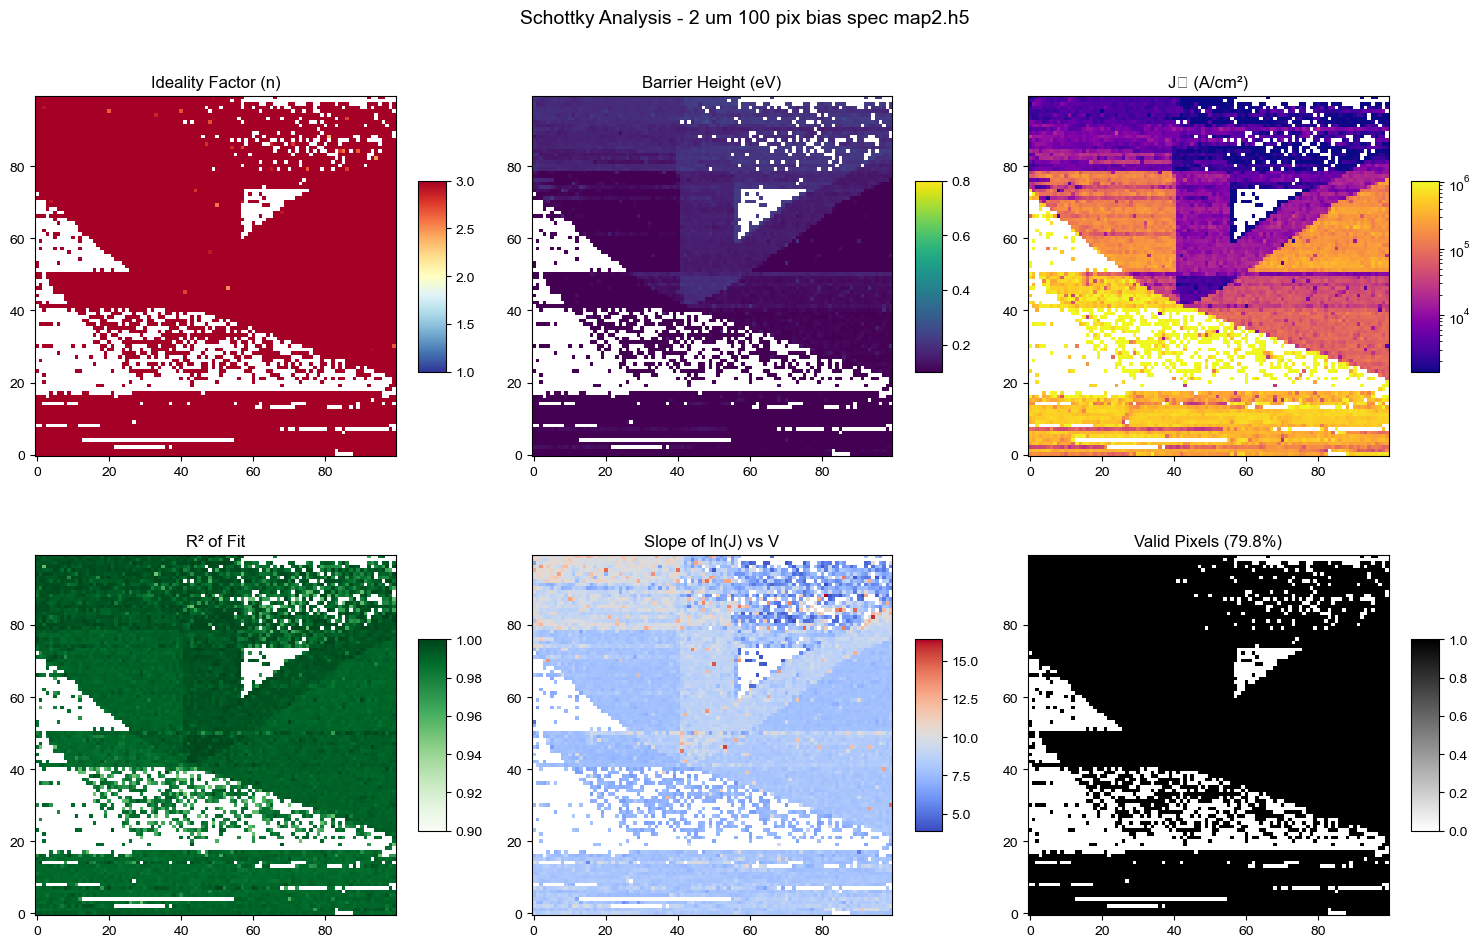

In [23]:
mapper = SchottkyMapper(h5map, schottky_analyzer, area_cm2)
mapper.fit_all_pixels(show_progress=True)  # 顯示進度條
mapper.plot_maps()
mapper.save_results()

## Read results

In [24]:
import numpy as np

# 設定你的檔案路徑
file_path = 'schottky_results/2 um 100 pix bias spec map2_results.npz'

# 載入檔案
data = np.load(file_path, allow_pickle=True)

# 提取各個陣列
n_map = data['n']
phi_map = data['phi']
j0_map = data['j0']
r2_map = data['r2']
slope_map = data['slope']
mask = data['mask']
bias = data['bias']

# 提取字典類型的資料 (stats)
# 因為字典被存入時會封裝成一個 0 維陣列，需要用 .item() 取出
stats = data['stats'].item()

# 測試印出
print(f"成功讀取檔案。有效像素比例: {stats['ratio']:.1f}%")
print(f"理想因子 (n) 均值: {stats['n_mean']:.3f}")

成功讀取檔案。有效像素比例: 79.8%
理想因子 (n) 均值: 4.775


In [26]:
import matplotlib.pyplot as plt
from matplotlib import rcParams

# Set the default sans-serif font to Arial
rcParams['font.sans-serif'] = ["Arial"]
rcParams['font.family'] = "sans-serif"

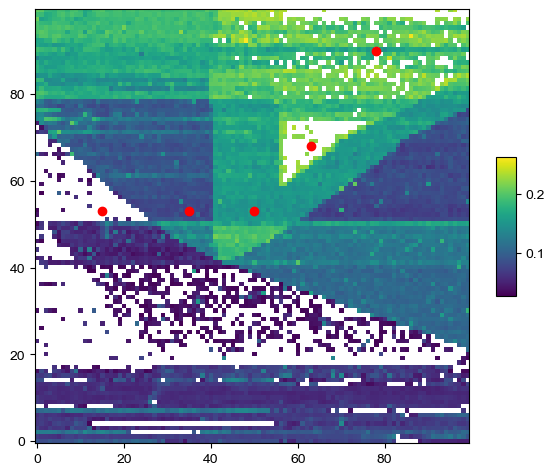

In [70]:
fig, ax = plt.subplots(1, 1, figsize = (7,6))
hmp = ax.imshow(phi_map, origin = 'lower')
cb = plt.colorbar(hmp, shrink = 0.3, aspect = 7)
points = [(15,53), (35, 53), (50,53), (63, 68), (78, 90)]
x_coords = [p[0] for p in points]
y_coords = [p[1] for p in points]
ax.scatter(x_coords, y_coords, c = 'red')

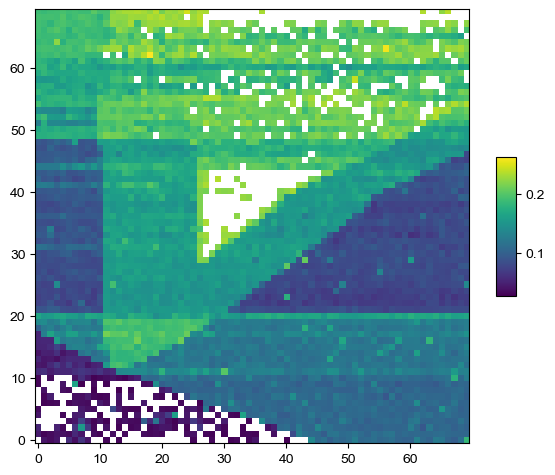

In [43]:
fig, ax = plt.subplots(1, 1, figsize = (7,6))
hmp = ax.imshow(phi_map[30:,30:], origin = 'lower')
cb = plt.colorbar(hmp, shrink = 0.3, aspect = 7)
x, y = 33, 38
#ax.scatter(x, y, c = 'red')

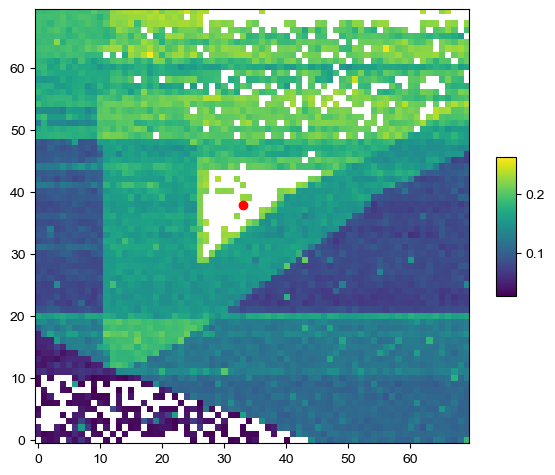

In [46]:
fig, ax = plt.subplots(1, 1, figsize = (7,6))
hmp = ax.imshow(phi_map[30:,30:], origin = 'lower')
cb = plt.colorbar(hmp, shrink = 0.3, aspect = 7)
x, y = 33, 38
ax.scatter(x, y, c = 'red')

In [47]:
phi_map[68, 64]

np.float64(nan)

In [51]:
current_map = h5map.current_map
current_map

array([[ 3.2221451e-05,  3.3260734e-05,  3.1130396e-05, ...,
         3.6547272e-07,  3.9937026e-07,  2.8371596e-07],
       [-4.2104191e-05, -3.8033821e-05, -4.2859883e-05, ...,
        -3.5860008e-05, -3.5723850e-05, -3.6706806e-05],
       [-4.2887870e-05, -4.2882803e-05, -4.2878302e-05, ...,
        -4.0526160e-05, -3.9097675e-05, -4.0230781e-05],
       ...,
       [ 3.3369866e-05,  3.3347740e-05,  3.3361746e-05, ...,
         2.4944025e-05,  2.3855615e-05,  2.3307930e-05],
       [ 3.3368859e-05,  3.3344950e-05,  3.3365061e-05, ...,
         2.5743204e-05,  2.4637033e-05,  2.3669396e-05],
       [ 3.3366006e-05,  3.3340784e-05,  3.3357279e-05, ...,
         2.6237802e-05,  2.5318504e-05,  2.4178536e-05]],
      shape=(500, 10000))

In [55]:
# --- 修正後的診斷腳本 ---
target_x, target_y = 63, 68
x_pixels = 100
idx = target_y * x_pixels + target_x

# 關鍵修正：確保 spectrum 的切片與 bias 同步 (skip_points=3)
# 假設你的 current_map 是原始資料 (500, total_pixels)
target_spectrum = current_map[3:, idx] 
target_bias = bias  # 這裡的 bias 應該已經是 [3:] 之後的 497 點

print(f"Bias shape: {target_bias.shape}")
print(f"Spectrum shape: {target_spectrum.shape}")

# 手動跑一次分析
res = schottky_analyzer.process_pixel(target_bias, target_spectrum, area_cm2)

if res:
    print(f"Successfully fitted!")
    print(f"R2: {res['r2']:.4f}, n: {res['n']:.2f}, phi_b: {res['phi_b']:.3f}, j0: {res['j0']:.3f}")
else:
    print("Fit failed (result is None)")

Bias shape: (497,)
Spectrum shape: (497,)
Successfully fitted!
R2: 0.9103, n: 23.72, phi_b: 0.213, j0: 1297.981
